In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import(
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [25]:
rng = np.random.default_rng(42)
saat = rng.uniform(1,10,40).round(1)
not_ = np.clip(30 + 6 * saat + rng.normal(0,5,40),0,100).round(1)

In [26]:
df = pd.DataFrame({"Calisma_Saati":saat,"Sinav_Notu":not_})

In [28]:
df.head()

,Calisma_Saati,Sinav_Notu
0,8.0,81.7
1,4.9,62.1
2,8.7,78.9
3,7.3,75.0
4,1.8,41.4


In [30]:
df.shape

(40, 2)

In [32]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Calisma_Saati,40.0,5.7975,2.598864,1.4,3.675,5.65,8.000,9.8
Sinav_Notu,40.0,64.8525,15.172935,36.1,51.025,63.05,78.825,89.9


In [33]:
df.isna().sum()

Calisma_Saati    0
Sinav_Notu       0
dtype: int64

In [34]:
df.columns

Index(['Calisma_Saati', 'Sinav_Notu'], dtype='object')

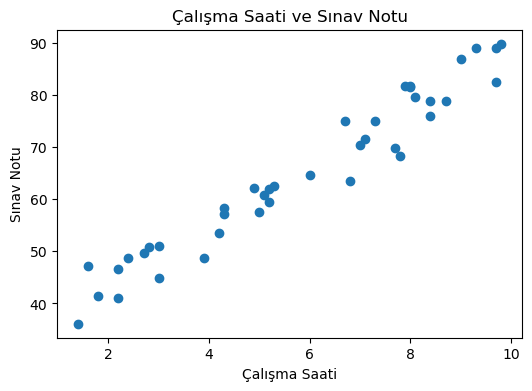

In [43]:
plt.figure(figsize=(6,4))
plt.scatter(df["Calisma_Saati"],df["Sinav_Notu"])
plt.xlabel("Çalışma Saati")
plt.ylabel("Sınav Notu")
plt.title("Çalışma Saati ve Sınav Notu")
plt.show()

In [45]:
df.head(2)

,Calisma_Saati,Sinav_Notu
0,8.0,81.7
1,4.9,62.1


In [53]:
## X ve y Ayrımı
# 1.Modelin kullanacagı bilgiler
# 2.Modelin tahmin etmesini istediğimiz sonuçlarımız
# girdi - ÇALISMA SAATİ -> FEATURE
# hedef - SINAV NOTUN -> TARGET
X = df[["Calisma_Saati"]]
y = df["Sinav_Notu"]


In [54]:
print("X şekli:",X.shape, "| y şekli: ",y.shape )

X şekli: (40, 1) | y şekli:  (40,)


In [59]:
# 80 / 20
# Eğitim/Test
#32/8

In [60]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [63]:
print("Egitim:", len(X_train))
print("Öğrenci | Test:", len(X_test))
print("öğrneci")
      

Egitim: 32
Öğrenci | Test: 8
öğrneci


In [64]:
from sklearn.linear_model import LinearRegression

In [65]:
model = LinearRegression()

In [66]:
model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [67]:
model.coef_

array([5.51835059])

In [68]:
model.intercept_

np.float64(33.333087144024404)

In [ ]:
NOT = 33.33 + 5.52 x SAAT
NOT = 30 + 6 X SAAT

In [69]:
y_pred = model.predict(X_test)

In [70]:
print(y_pred)

[70.30603613 66.44319071 49.88813893 62.02851024 43.26611821 70.85787119
 62.5803453  41.05877798]


In [73]:
mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)
print("MAE:",mae)
print("MSE:",mse)
print("R2:",r2)

MAE: 3.544528228995386
MSE: 17.490462692521533
R2: 0.8908209753324337


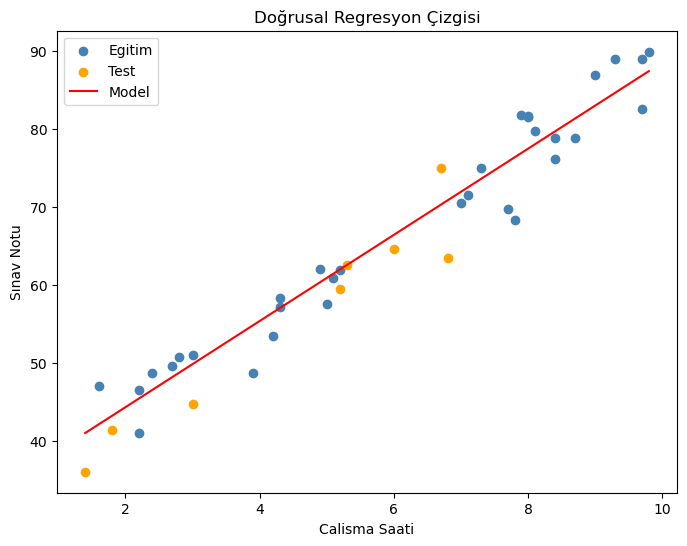

In [84]:
plt.figure(figsize=(8,6))
plt.scatter(X_train,y_train,color="steelblue",label="Egitim")
plt.scatter(X_test,y_test,color="orange",label="Test")
cizgi_x=pd.DataFrame({
    "Calisma_Saati":[
        X["Calisma_Saati"].min(),
        X["Calisma_Saati"].max()
    ]
})
plt.plot(
    cizgi_x,
    model.predict(cizgi_x),
    color="red",
    label="Model"
)
plt.xlabel("Calisma Saati")
plt.ylabel("Sınav Notu")
plt.title("Doğrusal Regresyon Çizgisi")
plt.legend()
plt.show()

In [86]:
yeni = pd.DataFrame({"Calisma_Saati":[2.0,5.0,8.0]})
for s,t in zip(yeni["Calisma_Saati"],model.predict(yeni)):
    print(f"{s:.0f} saat çalışan öğrencinin tahmini notu: {t:.1f}")

2 saat çalışan öğrencinin tahmini notu: 44.4
5 saat çalışan öğrencinin tahmini notu: 60.9
8 saat çalışan öğrencinin tahmini notu: 77.5
